In [90]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
import math
from numba import cuda

In [91]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(4), np.eye(4), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(4*X[i,2] + 4*X[i,3], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [92]:
#read from file
def read_data():
    df = pd.read_csv('data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y

L = [[0],[1],[2],[3],[0,1],[0,2],[0,3],[1,2],[1,3],[2,3],[0,1,2],[0,1,3],[0,2,3],[1,2,3],[0,1,2,3]]
names = []
for i in range(15):
    strs = ''
    inst = L[i]
    leni = len(inst)
    for j in range(leni):
        strs += str(inst[j]+1)
    strs = "x" + strs + '.npy'
    names.append(strs)
print(names)


['x1.npy', 'x2.npy', 'x3.npy', 'x4.npy', 'x12.npy', 'x13.npy', 'x14.npy', 'x23.npy', 'x24.npy', 'x34.npy', 'x123.npy', 'x124.npy', 'x134.npy', 'x234.npy', 'x1234.npy']


In [93]:
Truth = []
LiIMCV = []
LiCMC = []
VRFt = []
itrs = [0,13,14]
for i in range(15):
    w = nr.beta(1,1,10000)
    g = w/(1-w)
    print(names[i])
    input, output = read_data()
    input = input[:, L[i]]
    try: 
        input.shape[1]
    except:
        input = input[:,np.newaxis]
    dim = input.shape[1]
    N = input.shape[0]
    s = 2.5
    cov0 = np.linalg.inv(input.T @ input)

    def true_mean():
        const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
        t = np.sum(output[:, np.newaxis]*input, axis=0)
        expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
        def integrant(x):
            return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
        return scipy.integrate.quad(integrant, 0, np.inf)[0]

    tm = true_mean()
    Truth.append(tm)
    print(tm)
    nc = 4
    tar = gprior(dim)
    tar.set_parameters(cov0,input, g)
    pro = mix_normal(dim)
    a = tar.sampler(1000)
    try: 
        weights = np.load(names[i])[0]
        gs = np.load(names[i])[1]
        covs = np.array([gs[i]*cov0 for i in range(nc)])
    except:
        pro.em_algorithm(a,nc,input,3001)
        weights = pro.weights
        gs = pro.gs
        covs = np.array([gs[i]*cov0 for i in range(nc)])
        np.save(names[i], [weights, gs])

    Itrnum = 1100
    sample_size = 1000
    target = 'gprior'
    proposal = 'mix_normal'

    epoch = 100
    cmc_mean = []
    imhcv_mean = []
    print("start")

    for i in range(epoch):
        w = nr.beta(1,1,10000)
        g = w/(1-w)
        estcmc = BF(sample_size, weights, cov0, gs, input, output)
        tar = gprior(dim)
        tar.set_parameters(cov0, input, g)
        MyIM = IndMH(Itrnum, dim, target, proposal)
        est = BF(sample_size, weights, cov0, gs, input, output)
        MyIM.set_distribution_parameters(cov0, nc, weights, covs, input, g, gs)
        data = MyIM.IMH()
        est.sample_loader(data[0],data[1],data[2])
        m,v= est.IMCV0()
        imhcv_mean.append(m)
        datacmc = tar.sampler(sample_size)
        estcmc.cmc_loader(datacmc)
        mc,vc = estcmc.CMC()
        cmc_mean.append(mc)

    var_imhcv = np.array(imhcv_mean).var()
    var_cmc = np.array(cmc_mean).var()
    print('STD_IMCV:', np.sqrt(var_imhcv))
    print('STD_CMC:', np.sqrt(var_cmc))
    mean_imhcv = np.array(imhcv_mean).mean()
    mean_cmc = np.array(cmc_mean).mean()
    error_imhcv = mean_imhcv - tm
    error_cmc = mean_cmc - tm
    print('True mean:',tm)
    print('IMCV:',mean_imhcv,'error:', np.abs(error_imhcv))
    print('CMC:',mean_cmc, 'error:',np.abs(error_cmc))
    # print('MSECMC:',msecmc)
    LiIMCV.append(mean_imhcv)
    LiCMC.append(mean_cmc)
    VRFt.append(var_cmc/var_imhcv)
    print('VRF:',var_cmc/var_imhcv)

x1.npy
3.451032839159709e-84
start
STD_IMCV: 1.28743786755476e-86
STD_CMC: 4.322651853355007e-86
True mean: 3.451032839159709e-84
IMCV: 3.4603038135361426e-84 error: 9.270974376433543e-87
CMC: 3.4565710774119875e-84 error: 5.538238252278431e-87
VRF: 11.273219412025234
x2.npy
1.5346788637644075e-82
start
STD_IMCV: 2.054207157789949e-83
STD_CMC: 3.529952637070496e-83
True mean: 1.5346788637644075e-82
IMCV: 1.5327896262453656e-82 error: 1.8892375190418382e-85
CMC: 1.4993446726479222e-82 error: 3.5334191116485294e-84
VRF: 2.952903674736907
x3.npy
2.587027533242596e-74
start
STD_IMCV: 1.6006347013153933e-74
STD_CMC: 2.0595813843414388e-74
True mean: 2.587027533242596e-74
IMCV: 2.5206382182620115e-74 error: 6.638931498058456e-76
CMC: 2.650914138963247e-74 error: 6.388660572065087e-76
VRF: 1.65566877939836
x4.npy
6.198210673805663e-63
start
STD_IMCV: 3.603319940703151e-63
STD_CMC: 7.019587339971334e-63
True mean: 6.198210673805663e-63
IMCV: 5.922670475700198e-63 error: 2.7554019810546577e-64


In [94]:
Truth = np.array(Truth)
LiIMCV = np.array(LiIMCV)
LiCMC = np.array(LiCMC)
VRFt = np.array(VRFt)
BF_truth = Truth / Truth[0]
BF_imcv = LiIMCV / LiIMCV[0]
BF_cmc = LiCMC / LiCMC[0]
for i in range(15):
    print('$X_{', names[i][1:-4] ,'}$', '&',format(LiCMC[i],'.2e'), ' & ' ,format(LiIMCV[i],'.2e') ,' & ' , format(Truth[i],'.2e') , ' & ',np.round(VRFt[i],2), ' & ' , format(BF_cmc[i],'.2') ,  ' & ' , format(BF_imcv[i],'.2') ,  ' & ' , format(BF_truth[i],'.2') , '\\\\')

$X_{ 1 }$ & 3.46e-84  &  3.46e-84  &  3.45e-84  &  11.27  &  1.0  &  1.0  &  1.0 \\
$X_{ 2 }$ & 1.50e-82  &  1.53e-82  &  1.53e-82  &  2.95  &  4.3e+01  &  4.4e+01  &  4.4e+01 \\
$X_{ 3 }$ & 2.65e-74  &  2.52e-74  &  2.59e-74  &  1.66  &  7.7e+09  &  7.3e+09  &  7.5e+09 \\
$X_{ 4 }$ & 4.69e-63  &  5.92e-63  &  6.20e-63  &  3.8  &  1.4e+21  &  1.7e+21  &  1.8e+21 \\
$X_{ 12 }$ & 1.30e-82  &  1.34e-82  &  1.33e-82  &  6.89  &  3.8e+01  &  3.9e+01  &  3.8e+01 \\
$X_{ 13 }$ & 8.67e-75  &  9.27e-75  &  9.47e-75  &  14.15  &  2.5e+09  &  2.7e+09  &  2.7e+09 \\
$X_{ 14 }$ & 8.87e-64  &  8.55e-64  &  9.07e-64  &  3.85  &  2.6e+20  &  2.5e+20  &  2.6e+20 \\
$X_{ 23 }$ & 8.11e-74  &  7.66e-74  &  7.41e-74  &  2.69  &  2.3e+10  &  2.2e+10  &  2.1e+10 \\
$X_{ 24 }$ & 1.54e-61  &  1.46e-61  &  1.49e-61  &  7.05  &  4.4e+22  &  4.2e+22  &  4.3e+22 \\
$X_{ 34 }$ & 4.47e-53  &  2.02e-53  &  2.99e-53  &  11.94  &  1.3e+31  &  5.8e+30  &  8.7e+30 \\
$X_{ 123 }$ & 4.88e-74  &  3.29e-74  &  4.00e-74  &  0

In [95]:

    # 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15
A = [[0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], #1
     [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0], #2
     [0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0], #3
     [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0], #4
     [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0], #5
     [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], #6
     [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0], #7
     [0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0], #8
     [0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0], #9
     [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0], #10
     [0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1], #11
     [0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1], #12
     [0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1], #13
     [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1], #14
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0]] #15



In [96]:
A = np.array(A)
transp = np.sum(A, axis=1)
choices = np.array([i for i in range(15)])
nitrs = 10000
init = 1
state = init
tar_state = LiIMCV[state]
pro_state = 1/transp[state]
states=[]
pmap = np.zeros((15,nitrs+1))
for i in range(nitrs):
    propoesed = np.random.choice(choices, p=A[state]/np.sum(A[state]))
    sample = np.random.uniform(0.0, 1.0, 1)
    ratio_tar = LiIMCV[propoesed]/tar_state
    ratio_pro = transp[propoesed]*pro_state
    ratio = min(1, ratio_tar*ratio_pro)
    if sample <= ratio:
        state = propoesed
        tar_state = LiIMCV[state]
        pro_state = 1/transp[state]
    pmap[:,i+1] = pmap[:,i]
    pmap[state,i+1] += 1
    states.append(state)

print(pmap[:,-1])
print


[0.000e+00 1.000e+00 0.000e+00 0.000e+00 1.000e+00 0.000e+00 0.000e+00
 0.000e+00 8.000e+00 4.376e+03 0.000e+00 4.000e+00 1.122e+03 4.133e+03
 3.550e+02]


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

<Axes: >

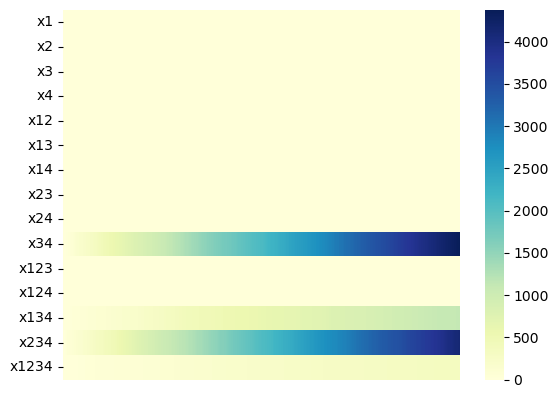

In [97]:
import seaborn as sns
names_new = [names[i][:-4] for i in range(15)]
sns.heatmap(pmap, cmap="YlGnBu", yticklabels=names_new, xticklabels=False)